In [3]:
import pandas as pd
import numpy as np         
import matplotlib.pyplot as plt   
import seaborn as sns  
from sklearn.ensemble import RandomForestClassifier

In [4]:

df = pd.read_csv("Summer_Diabari.csv")
df.head()

,Month,Gender,Age,Education,Spend_Time_(min),Transportation,Thermal_Comfort_(PMV),Preference_Vote,Visual_Comfort,Seating_Place,Seating_Surface,Weather_Condition,Location_Name,Temperature_(°C),Humidity_(%),CO₂_(PPM),Lighting_Intensity_(Lux),Surface_Temperature_(°C),Air_Velocity_(km/h),Resident
0,April,Male,Youth,BSC,30-60,Car,Neutral,Slightly Cooler,Neutral,Under Shadow,Plastic,Partial Sunshine,Uttara North,33.0,68.0,414,5300,31.0,19.0,Local
1,April,Male,Youth,MSC,0-15,Walk,Neutral,No Change,Adequate,Partially Sunlight,Plastic,Partial Sunshine,Uttara North,32.0,67.0,463,11000,33.0,19.0,Local
2,April,Male,Youth,BSC,30-60,Auto,Warm,Slightly Cooler,Adequate,Direct Sunlight,Concrete,Sunshine,Uttara North,32.0,67.0,431,999,39.0,19.0,Outside
3,April,Male,Teenager,HSC,15- 30,Walk,Slightly Warm,No Change,Adequate,Direct Sunlight,Concrete,Partial Sunshine,Uttara North,32.0,67.0,422,10000,39.0,19.0,Outside
4,April,Male,Teenager,HSC,15- 30,Walk,Neutral,No Change,Adequate,Direct Sunlight,Concrete,Sunshine,Uttara North,33.0,64.0,431,9288,38.0,18.0,Outside


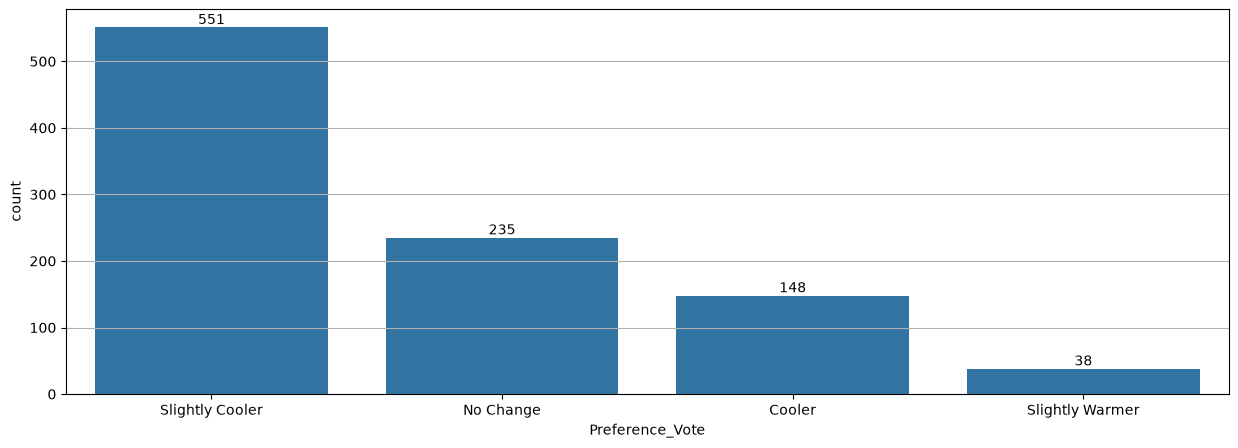

In [7]:
# Adding Values to Seaborn Count Plots
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))
plt.grid()
ax = sns.countplot(data=df, x='Preference_Vote', )

for label in ax.containers:
    ax.bar_label(label)
    
plt.show()

In [9]:

df.columns = df.columns.str.strip()
df["Education"] = pd.factorize(df['Education'])[0].astype(np.uint8)
df["Month"] = pd.factorize(df['Month'])[0].astype(np.uint8)
df["Gender"] = pd.factorize(df['Gender'])[0].astype(np.uint8)
df["Age"] = pd.factorize(df['Age'])[0].astype(np.uint8)
df["Spend_Time_(min)"] = pd.factorize(df['Spend_Time_(min)'])[0].astype(np.uint8)
df["Transportation"] = pd.factorize(df['Transportation'])[0].astype(np.uint8)
df["Thermal_Comfort_(PMV)"] = pd.factorize(df['Thermal_Comfort_(PMV)'])[0].astype(np.uint8)
df["Preference_Vote"] = pd.factorize(df['Preference_Vote'])[0].astype(np.uint8)
df["Visual_Comfort"] = pd.factorize(df['Visual_Comfort'])[0].astype(np.uint8)
df["Seating_Surface"] = pd.factorize(df['Seating_Surface'])[0].astype(np.uint8)
df["Transportation"] = pd.factorize(df['Transportation'])[0].astype(np.uint8)
df["Weather_Condition"] = pd.factorize(df['Weather_Condition'])[0].astype(np.uint8)
df["Location_Name"] = pd.factorize(df['Location_Name'])[0].astype(np.uint8)
df["Resident"] = pd.factorize(df['Resident'])[0].astype(np.uint8)
df["Seating_Place"] = pd.factorize(df['Seating_Place'])[0].astype(np.uint8)

In [11]:

df.head()  

,Month,Gender,Age,Education,Spend_Time_(min),Transportation,Thermal_Comfort_(PMV),Preference_Vote,Visual_Comfort,Seating_Place,Seating_Surface,Weather_Condition,Location_Name,Temperature_(°C),Humidity_(%),CO₂_(PPM),Lighting_Intensity_(Lux),Surface_Temperature_(°C),Air_Velocity_(km/h),Resident
0,0,0,0,0,0,0,0,0,0,0,0,0,0,33.0,68.0,414,5300,31.0,19.0,0
1,0,0,0,1,1,1,0,1,1,1,0,0,0,32.0,67.0,463,11000,33.0,19.0,0
2,0,0,0,0,0,2,1,0,1,2,1,1,0,32.0,67.0,431,999,39.0,19.0,1
3,0,0,1,2,2,1,2,1,1,2,1,0,0,32.0,67.0,422,10000,39.0,19.0,1
4,0,0,1,2,2,1,0,1,1,2,1,1,0,33.0,64.0,431,9288,38.0,18.0,1


In [13]:
#Filter any variables with low variance (close to zero) to avoid overfitting
df.var()


Month                       4.293731e+00
Gender                      1.561667e-01
Age                         9.296120e-01
Education                   2.412509e+00
Spend_Time_(min)            1.273842e+00
Transportation              2.022564e+00
Thermal_Comfort_(PMV)       3.144663e+00
Preference_Vote             7.631213e-01
Visual_Comfort              1.478163e+00
Seating_Place               6.401953e-01
Seating_Surface             2.641046e+00
Weather_Condition           7.546588e-01
Location_Name               7.527039e-01
Temperature_(°C)            9.235149e+01
Humidity_(%)                6.430473e+02
CO₂_(PPM)                   1.063341e+03
Lighting_Intensity_(Lux)    9.336360e+07
Surface_Temperature_(°C)    4.419320e+04
Air_Velocity_(km/h)         1.997165e+02
Resident                    6.469551e-01
dtype: float64

In [15]:

inputs = df.drop(['Preference_Vote',], axis=1)

In [17]:
target = df['Preference_Vote']

In [19]:
inputs

,Month,Gender,Age,Education,Spend_Time_(min),Transportation,Thermal_Comfort_(PMV),Visual_Comfort,Seating_Place,Seating_Surface,Weather_Condition,Location_Name,Temperature_(°C),Humidity_(%),CO₂_(PPM),Lighting_Intensity_(Lux),Surface_Temperature_(°C),Air_Velocity_(km/h),Resident
0,0,0,0,0,0,0,0,0,0,0,0,0,33.0,68.0,414,5300,31.0,19.0,0
1,0,0,0,1,1,1,0,1,1,0,0,0,32.0,67.0,463,11000,33.0,19.0,0
2,0,0,0,0,0,2,1,1,2,1,1,0,32.0,67.0,431,999,39.0,19.0,1
3,0,0,1,2,2,1,2,1,2,1,0,0,32.0,67.0,422,10000,39.0,19.0,1
4,0,0,1,2,2,1,0,1,2,1,1,0,33.0,64.0,431,9288,38.0,18.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
967,7,0,3,2,1,5,5,2,2,1,1,0,33.0,67.0,444,1271,28.3,2.0,0
968,7,0,3,1,0,0,5,0,0,0,0,0,32.1,75.0,423,1332,32.4,2.0,2
969,7,0,3,2,0,0,0,0,0,0,0,0,32.1,75.0,423,1332,32.4,2.0,2
970,7,0,3,1,0,0,2,1,0,0,0,0,32.1,75.0,423,1332,32.4,1.1,2


In [21]:
target

0      0
1      1
2      0
3      1
4      1
      ..
967    2
968    0
969    1
970    0
971    0
Name: Preference_Vote, Length: 972, dtype: uint8

In [23]:
from sklearn.model_selection import train_test_split
X = inputs  
y = target

In [25]:
df['Preference_Vote'].value_counts()

Preference_Vote
0    551
1    235
2    148
3     38
Name: count, dtype: int64

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.metrics import mean_squared_error


In [29]:
y.value_counts()

Preference_Vote
0    551
1    235
2    148
3     38
Name: count, dtype: int64

In [31]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

In [33]:
from imblearn.combine import SMOTETomek
from sklearn.model_selection import train_test_split

# First Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [35]:
y_train.value_counts() #Check the DV number before SMOTE

Preference_Vote
0    437
1    188
2    120
3     32
Name: count, dtype: int64

In [37]:
# Apply SMOTEENN to the training dataset
resampler = SMOTETomek(random_state=42)
X_train_recomputed, y_train_recomputed = resampler.fit_resample(X_train, y_train)

In [39]:
# Assign the resampled data back to the original variables
X_train, y_train = X_train_recomputed, y_train_recomputed



In [41]:
y_train.value_counts() #Check the DV number after SMOTE

Preference_Vote
3    399
1    382
2    364
0    351
Name: count, dtype: int64

In [46]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define parameter grid
param_grid = {
    "n_estimators": [100, 200, 300],
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 10, 15],
    "min_samples_split": [2, 4, 6],
    "min_samples_leaf": [1, 2, 4]
}

# training model on the define params with GridSearchCV
rfc_tree = RandomForestClassifier()
rfc_cv = GridSearchCV(rfc_tree, param_grid,scoring="accuracy",
                       n_jobs=-1,verbose=1, cv=5)

rfc_cv.fit(X_train, y_train)
predictions = rfc_cv.predict(X_test)
optimal_params = rfc_cv.best_params_
print(f"\nOptimal paramters: ({optimal_params})")

print("\n====BEST MODEL SCORE====")
print('Best model score: ', rfc_cv.best_score_)

Fitting 5 folds for each of 162 candidates, totalling 810 fits

Optimal paramters: ({'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200})

====BEST MODEL SCORE====
Best model score:  0.8341984126984127


In [45]:
rfc = RandomForestClassifier(
    criterion='gini',
    max_depth=15,
    min_samples_leaf=1,
    min_samples_split=2,
    n_estimators=200,
    max_features='sqrt',
    random_state=42
)


In [47]:
rfc.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [49]:
rfc.score(X_train, y_train)

0.9973262032085561

In [51]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestClassifier

y_predict = rfc.predict(X_test)
print('Accuracy score:',accuracy_score(y_test, y_predict))

Accuracy score: 0.8743315508021391


In [53]:
y_predict = rfc.predict(X_test)

In [55]:
y_predict = rfc.predict(X_test)
mse = mean_squared_error(y_test, y_predict)
print("MSE: %.2f" % mse)
print("RMSE: %.2f" % (mse**(1/2.0)))

MSE: 0.38
RMSE: 0.62


In [57]:
from sklearn.metrics import accuracy_score,confusion_matrix,\
 classification_report


from sklearn import metrics #Import scikit-learn metrics module for accuracy calculation
print("Accuracy:",metrics.accuracy_score(y_test, y_predict))

cm = confusion_matrix(y_test, y_predict)
print("Confusion matrix:")
print(cm)

Accuracy: 0.8743315508021391
Confusion matrix:
[[73  8  5  1]
 [ 7 79  2  1]
 [ 8  4 78  3]
 [ 5  2  1 97]]


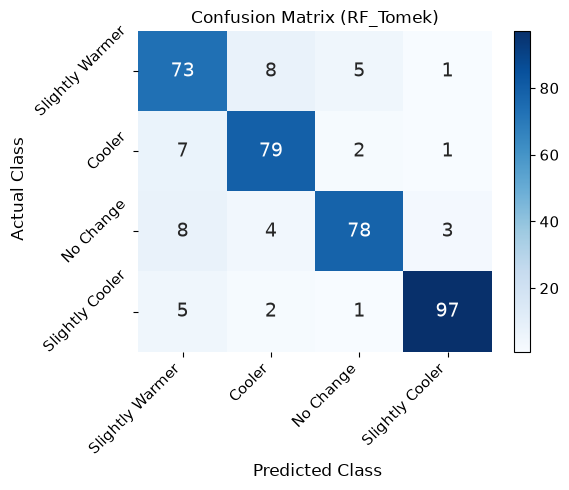

Saved successfully: D:\DiaBari X Nymesir\Confusion matrix\RF_Tomek.jpeg


In [59]:
# Define class names
class_names = ["Slightly Cooler", "No Change", "Cooler", "Slightly Warmer"]
# Create the confusion matrix
cm = confusion_matrix(y_test, y_predict)

# Plot the confusion matrix using a heatmap
plt.figure(figsize=(6, 5))
heatmap = sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', xticklabels=class_names[::-1], yticklabels=class_names[::-1], annot_kws={"fontsize": 14})

# Increase font size for annotations
heatmap.set_yticklabels(heatmap.get_yticklabels(), fontsize=11, rotation=45)  # Rotate y-axis labels
heatmap.set_xticklabels(heatmap.get_xticklabels(), fontsize=11, rotation=45, ha='right')  # Rotate x-axis labels and align them to the right

plt.title('Confusion Matrix (RF_Tomek)', fontsize=12)  # Increase title font size
plt.xlabel(' Predicted Class', fontsize=12)  # Increase x-axis label font size
plt.ylabel(' Actual Class', fontsize=12)  # Increase y-axis label font size

# Increase font size for the values inside each class
for text in heatmap.texts:
    text.set_fontsize(14)

# Remove the duplicate colorbar
plt.gcf().get_axes()[1].remove()

# Create a separate colorbar figure and adjust its position
cbar = plt.colorbar(heatmap.collections[0])
cbar.ax.tick_params(labelsize=11)  # Increase colorbar tick font size

plt.tight_layout()

# ---- SAVE FIGURE (Added Here) ----
save_path = r"D:\DiaBari X Nymesir\Confusion matrix\RF_Tomek.jpeg"   # your file location/name
plt.savefig(save_path, dpi=600, format='jpeg', bbox_inches='tight')

# Show plot 
plt.show()

print("Saved successfully:", save_path)

In [61]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.78      0.84      0.81        87
           1       0.85      0.89      0.87        89
           2       0.91      0.84      0.87        93
           3       0.95      0.92      0.94       105

    accuracy                           0.87       374
   macro avg       0.87      0.87      0.87       374
weighted avg       0.88      0.87      0.88       374



In [63]:
#Lets encode target labels (y) with values between 0 and n_classes-1.
#We will use the LabelEncoder to do this. 
from sklearn.preprocessing import LabelEncoder
label_encoder=LabelEncoder()
label_encoder.fit(y)
y=label_encoder.transform(y)
classes=label_encoder.classes_

In [65]:
y_predict = rfc.predict(X_test)
pred_prob = rfc.predict_proba(X_test)

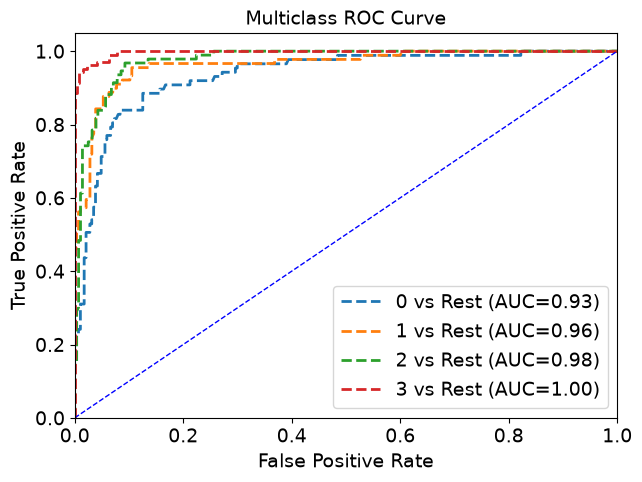

Saved successfully: D:\DiaBari X Nymesir\ROC_AUC\RF_Tomek.jpeg


In [67]:
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc

# Binarize labels
y_test_binarized = label_binarize(y_test, classes=np.unique(y_test))

# Adjustable parameters
fig_width = 7       # change figure width
fig_height = 5       # change figure height
label_font = 14      # change axis label size
title_font = 14       # change title size
legend_font = 14      # change legend size
line_width = 2        # line thickness

# ROC calculations
fpr = {}
tpr = {}
thresh = {}
roc_auc = dict()

n_class = classes.shape[0]

# Create figure with adjustable size
plt.figure(figsize=(fig_width, fig_height))

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test_binarized[:, i], pred_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(
        fpr[i], tpr[i],
        linestyle='--',
        linewidth=line_width,
        label='%s vs Rest (AUC=%0.2f)' % (classes[i], roc_auc[i])
    )

# Diagonal line
plt.plot([0, 1], [0, 1], 'b--', linewidth=1)

plt.xlim([0, 1])
plt.ylim([0, 1.05])

plt.title('Multiclass ROC Curve', fontsize=title_font)
plt.xlabel('False Positive Rate', fontsize=label_font)
plt.ylabel('True Positive Rate', fontsize=label_font)

plt.legend(loc='lower right', fontsize=legend_font)
plt.tick_params(axis='both', labelsize=label_font)

# ---- SAVE FIGURE (Added Here) ----
save_path = r"D:\DiaBari X Nymesir\ROC_AUC\RF_Tomek.jpeg"   # your file location/name
plt.savefig(save_path, dpi=600, format='jpeg', bbox_inches='tight')

# Show plot 
plt.show()

print("Saved successfully:", save_path)


In [69]:
from sklearn.metrics import log_loss
logloss = log_loss(y_test, rfc.predict_proba(X_test))
logloss

0.4909156427364514

Text(0.5, 1.0, 'Random Forest Feature Importances (MDI)')

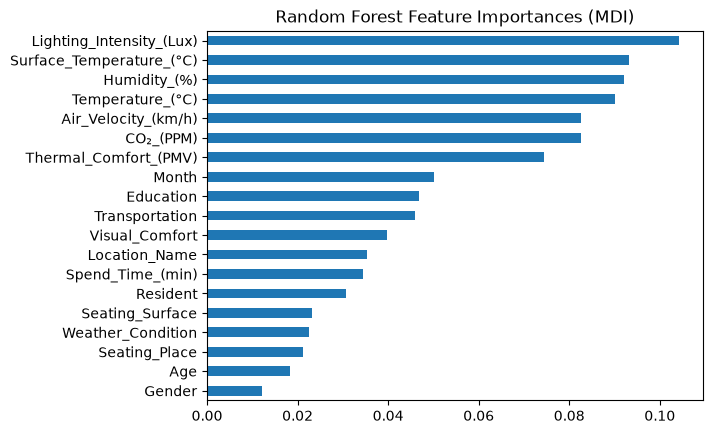

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
feat_importances = pd.Series(rfc.feature_importances_, index = X_train.columns).sort_values(ascending = True)
feat_importances.plot(kind = 'barh')
plt.title('Random Forest Feature Importances (MDI)')

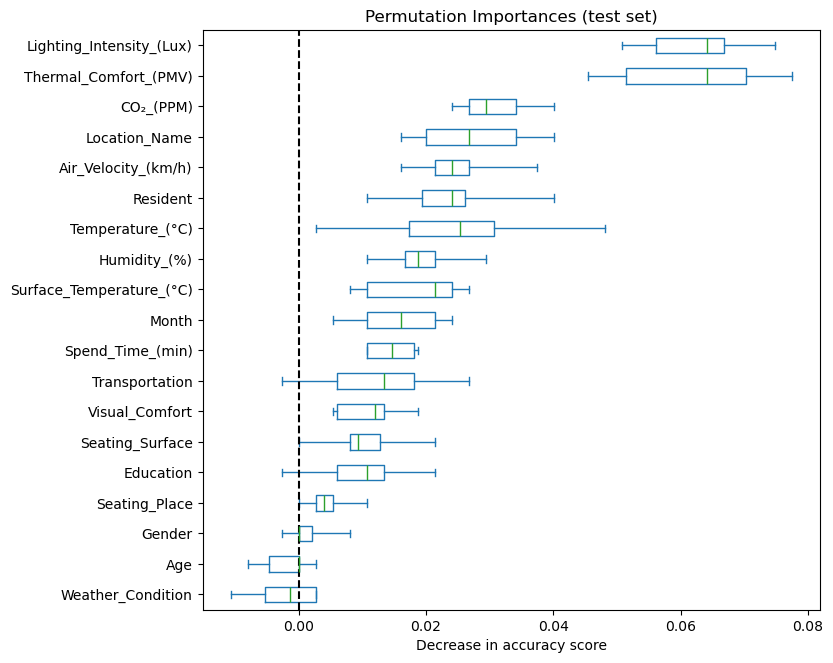

<Figure size 2500x1500 with 0 Axes>

In [76]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rfc, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2)

sorted_importances_idx = result.importances_mean.argsort()
importances = pd.DataFrame(
    result.importances[sorted_importances_idx].T,
    columns=X.columns[sorted_importances_idx],)
ax = importances.plot.box(vert=False, whis=10)
ax.set_title("Permutation Importances (test set)")
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in accuracy score")
ax.figure.tight_layout()

import matplotlib.pyplot as plt
fig = plt.gcf()
plt.figure(figsize=(25,15))
figsize = fig.get_size_inches()
fig.set_size_inches(figsize * 1.5)

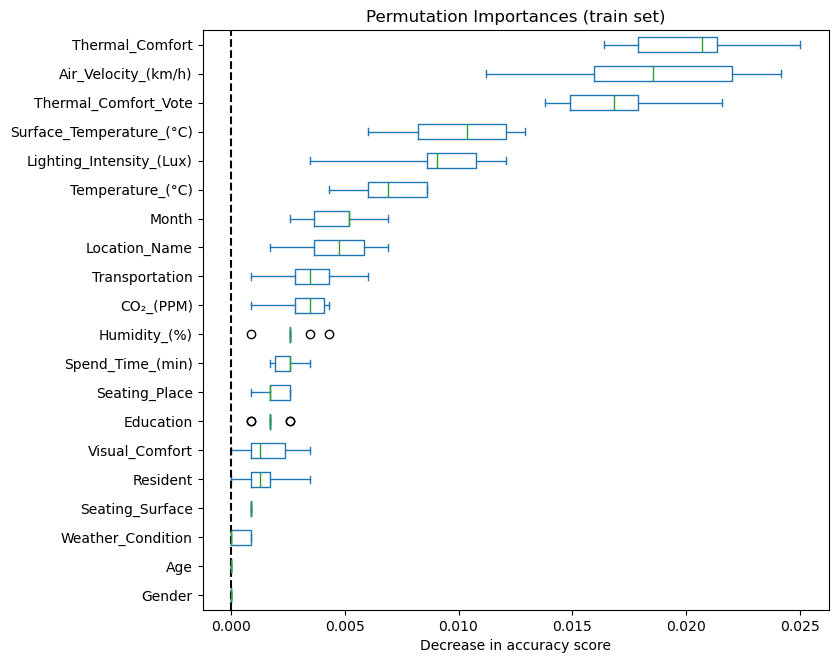

<Figure size 2500x1500 with 0 Axes>

In [104]:
result = permutation_importance(
    rfc, X_train, y_train, n_repeats=10, random_state=42, n_jobs=2)

sorted_importances_idx = result.importances_mean.argsort()
importances = pd.DataFrame(
    result.importances[sorted_importances_idx].T,
    columns=X.columns[sorted_importances_idx],)
ax = importances.plot.box(vert=False, whis=10)
ax.set_title("Permutation Importances (train set)")
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in accuracy score")
ax.figure.tight_layout()

import matplotlib.pyplot as plt
fig = plt.gcf()
plt.figure(figsize=(25,15))
figsize = fig.get_size_inches()
fig.set_size_inches(figsize * 1.5)

In [73]:
import numpy as np
import pandas as pd

In [75]:
import shap
explainer = shap.TreeExplainer(rfc)
shap_values = explainer.shap_values(X_test)

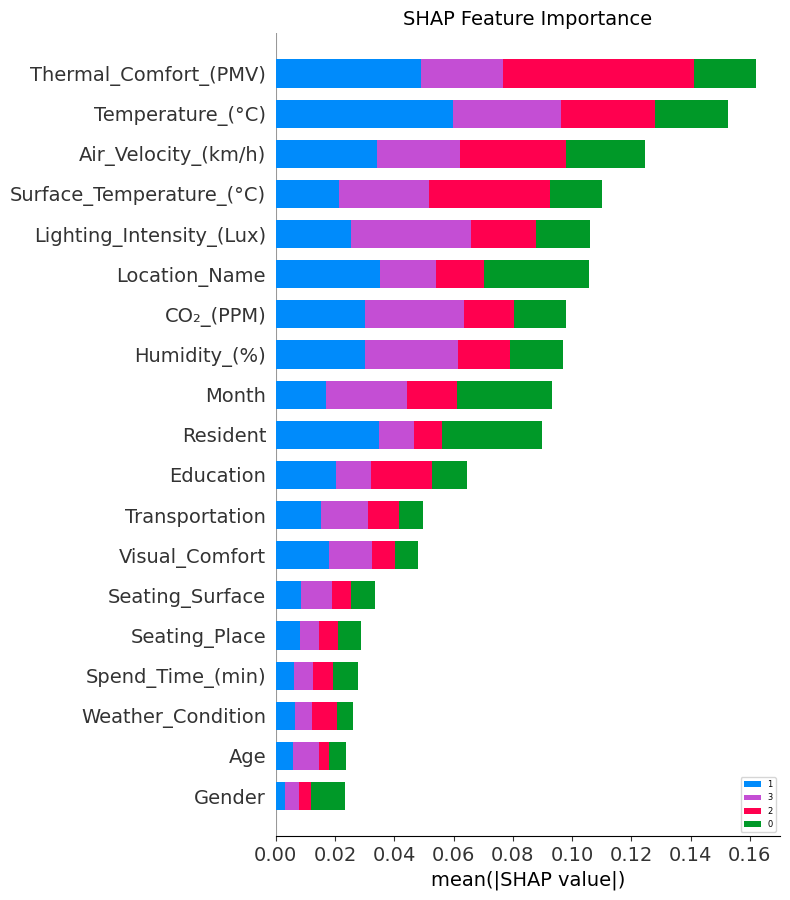

Saved successfully: D:\DiaBari X Nymesir\SHAP\RF_Tomek.jpeg


In [81]:
import shap
import matplotlib.pyplot as plt

# ---- Adjustable parameters ----
fig_width = 8        # width of the plot
fig_height = 4        # height of the plot
label_font = 14       # axis label + feature name font size
tick_font = 14        # tick label size
title_font = 14       # title font size
bar_font = 6          # class name / bar text size

# ---- Create figure before SHAP plot ----
plt.figure(figsize=(fig_width, fig_height))

# ---- SHAP summary bar plot ----
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    class_names=rfc.classes_,
    show=False  # important to modify AFTER creation
)

# ---- Apply size modifications ----
plt.title("SHAP Feature Importance", fontsize=title_font)
plt.xlabel("mean(|SHAP value|)", fontsize=label_font)

plt.xticks(fontsize=tick_font)
plt.yticks(fontsize=label_font)

# If class names exist, increase their font size
plt.legend(fontsize=bar_font)

plt.tight_layout()
# ---- SAVE FIGURE (Added Here) ----
save_path = r"D:\DiaBari X Nymesir\SHAP\RF_Tomek.jpeg"   # your file location/name
plt.savefig(save_path, dpi=600, format='jpeg', bbox_inches='tight')

# Show plot 
plt.show()

print("Saved successfully:", save_path)


In [84]:
#importing random forest classifier and recursive feature elemenation
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score

scores = []
for i in range(1,X.shape[1]):
    rfc = RFE(RandomForestClassifier(n_estimators=100, random_state=42), n_features_to_select= i)
    rfc.fit(X_train, y_train)

    y_predict = rfc.predict(X_test)
    #printing the number of selected features and its accuracy after each iteration
    print('Number of Selected features: ', i)
    sc = accuracy_score(y_test, y_predict)
    print('accuracy score:', sc)
    print()
    scores.append(sc)

Number of Selected features:  1
accuracy score: 0.5508021390374331

Number of Selected features:  2
accuracy score: 0.6844919786096256

Number of Selected features:  3
accuracy score: 0.7112299465240641

Number of Selected features:  4
accuracy score: 0.7566844919786097

Number of Selected features:  5
accuracy score: 0.7566844919786097

Number of Selected features:  6
accuracy score: 0.7620320855614974

Number of Selected features:  7
accuracy score: 0.7914438502673797

Number of Selected features:  8
accuracy score: 0.8074866310160428

Number of Selected features:  9
accuracy score: 0.820855614973262

Number of Selected features:  10
accuracy score: 0.8288770053475936

Number of Selected features:  11
accuracy score: 0.8262032085561497

Number of Selected features:  12
accuracy score: 0.8556149732620321

Number of Selected features:  13
accuracy score: 0.8449197860962567

Number of Selected features:  14
accuracy score: 0.8556149732620321

Number of Selected features:  15
accuracy sc

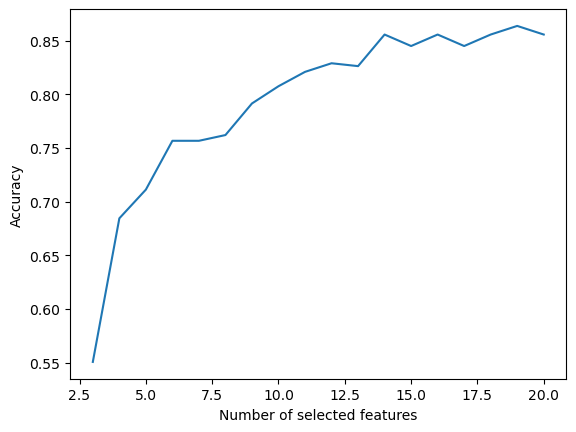

In [86]:
plt.figure()
plt.xlabel("Number of selected features")
plt.ylabel("Accuracy")

plt.plot(range(3, len(scores) + 3), scores)

plt.show()


In [88]:
rfc.get_support()

array([ True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])

In [90]:
features = X_train.columns[rfc.get_support()]
features

Index(['Month', 'Age', 'Education', 'Spend_Time_(min)', 'Transportation',
       'Thermal_Comfort_(PMV)', 'Visual_Comfort', 'Seating_Place',
       'Seating_Surface', 'Weather_Condition', 'Location_Name',
       'Temperature_(°C)', 'Humidity_(%)', 'CO₂_(PPM)',
       'Lighting_Intensity_(Lux)', 'Surface_Temperature_(°C)',
       'Air_Velocity_(km/h)', 'Resident'],
      dtype='object')

In [92]:
excluded_feature = list(set(X_train.columns) - set(features))
print(excluded_feature)

['Gender']


In [94]:
#drop features from X
X = X.drop(['Gender'], axis=1)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

parameters = [
    "Gender",
    "Age",
    "Education",
    "Spend_Time_(min)",
    "Transportation",
    "Thermal_Comfort_(PMV)",
    "Visual_Comfort",
    "Seating_Place",
    "Seating_Surface",
    "Weather_Condition",
    "Location_Name",
    "Temperature_(°C)",
    "Humidity_(%)",
    "CO₂_(PPM)",
    "Lighting_Intensity_(Lux)",
    "Surface_Temperature_(°C)",
    "Air_Velocity_(km/h)",
    "Resident"
]

# Initialize a dictionary to store the sensitivity coefficients
sensitivity_coefficients = {}

# Perform sensitivity analysis for each parameter
for parameter in parameters:
    results = []
    for value in np.linspace(0.4, 2.0, 10):  # Vary the parameter value from 0.5 to 2.0
        X_test_modified = X_test.copy()  # Create a copy of the original test data
        X_test_modified[parameter] = X_test_modified[parameter] * value  # Modify the parameter value

        # Predict using the modified data
        y_predict_modified = rfc.predict(X_test_modified)

        # Evaluate the model with the modified parameter
        result = rfc.score(X_test_modified, y_test)
        results.append(result)

    # Calculate sensitivity coefficient as the range of model performance
    sensitivity_coefficient = max(results) - min(results)
    sensitivity_coefficients[parameter] = sensitivity_coefficient

# Sort parameters by sensitivity coefficient in descending order
sorted_parameters = sorted(sensitivity_coefficients, key=sensitivity_coefficients.get, reverse=True)

# Print the sensitivity coefficients for each parameter
for parameter in sorted_parameters:
    print(f'{parameter}: {sensitivity_coefficients[parameter]}')

# Plot all sensitivity analyses in a single frame
plt.figure(figsize=(7, 6), dpi=150)
for parameter in sorted_parameters:
    results = []
    for value in np.linspace(0.5, 2.0, 10):  # Vary the parameter value from 0.5 to 2.0
        X_test_modified = X_test.copy()  # Create a copy of the original test data
        X_test_modified[parameter] = X_test_modified[parameter] * value  # Modify the parameter value

        # Predict using the modified data
        y_predict_modified = rfc.predict(X_test_modified)

        # Evaluate the model with the modified parameter
        result = rfc.score(X_test_modified, y_test)
        results.append(result)

    plt.plot(np.linspace(0.4, 2.0, 10), results, label=parameter)


plt.xlabel('Multiplier Value')
plt.ylabel('Accuracy')
plt.title('Sensitivity Analysis (SMOTE_TOMEK)')
plt.legend()

# ---- SAVE FIGURE FIRST ----

# Then display
plt.show()

Surface_Temperature_(°C): 0.06149732620320858
Temperature_(°C): 0.05882352941176461
Lighting_Intensity_(Lux): 0.048128342245989386
Resident: 0.045454545454545525
Air_Velocity_(km/h): 0.04278074866310155
Humidity_(%): 0.03475935828877008
Thermal_Comfort_(PMV): 0.03208556149732622
CO₂_(PPM): 0.0267379679144385
Spend_Time_(min): 0.018716577540107027
Transportation: 0.018716577540106916
Location_Name: 0.016042780748663166
Visual_Comfort: 0.016042780748663055
Seating_Place: 0.016042780748663055
Seating_Surface: 0.016042780748663055
Education: 0.013368983957219194
Weather_Condition: 0.008021390374331472
Gender: 0.0
Age: 0.0
